# Exploratory Data Analysis and Insights on Forest Fires Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to explore environmental data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading and inspecting a CSV file
- Checking missing and duplicate values
- Selecting rows and columns
- Exploring calendar and weather variables
- Filtering and sorting records
- Grouping and aggregating data
- Creating derived columns
- Applying a simple logarithmic transformation
- Examining correlations
- Creating basic visualizations
- Exporting an analyzed DataFrame


## About the Dataset

The **ForestFires.csv** dataset contains **517 forest-fire records** from Montesinho Natural Park in northeastern Portugal.

It contains **13 columns**:

| Column | Description |
|---|---|
| `X`, `Y` | Spatial coordinates within the park map |
| `month` | Month of the year |
| `day` | Day of the week |
| `FFMC` | Fine Fuel Moisture Code |
| `DMC` | Duff Moisture Code |
| `DC` | Drought Code |
| `ISI` | Initial Spread Index |
| `temp` | Temperature in degrees Celsius |
| `RH` | Relative humidity percentage |
| `wind` | Wind speed in kilometres per hour |
| `rain` | Outside rain in millimetres per square metre |
| `area` | Burned forest area in hectares |

### Important Observation

Many records have an `area` value of zero, and the positive burned-area values are strongly skewed. This makes the dataset useful for practicing filtering, grouping, visualization, and a simple `log1p()` transformation.

This assignment focuses on exploratory data analysis. Predicting burned area is a difficult regression problem and is outside the scope of this notebook.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/162/forest+fires)  
**License:** CC BY 4.0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate Pandas workflow. You will compare fire records across months and days, examine weather conditions, create simple categories, transform a skewed variable, and summarize relationships with charts and correlations.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **ForestFires.csv** into a DataFrame named `df`.


In [1]:
import pandas as pd
df = pd.read_csv('D:\Liha-Tech Assignments\Pandas\Forest_Fires\ForestFires.csv')

### Question 2
Display the first **5 rows** of the dataset.


In [2]:
df.head()

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


### Question 3
Display the last **5 rows** of the dataset.


In [4]:
df.tail()

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
512,4,3,aug,sun,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,aug,sun,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29
514,7,4,aug,sun,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16
515,1,4,aug,sat,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00
516,6,3,nov,tue,79.5,3.0,106.7,1.1,11.8,31,4.5,0.0,0.00


### Question 4
Find the total number of **rows and columns** in the dataset.


In [5]:
df.shape

(517, 13)

### Question 5
Display all the **column names** in the dataset.


In [6]:
df.columns

Index(['X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI', 'temp', 'RH',
       'wind', 'rain', 'area'],
      dtype='str')

### Question 6
Display the **data type of each column**.


In [7]:
df.dtypes

X          int64
Y          int64
month        str
day          str
FFMC     float64
DMC      float64
DC       float64
ISI      float64
temp     float64
RH         int64
wind     float64
rain     float64
area     float64
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB


## 2. Checking Data Quality

### Question 8
Display the number of **missing values in each column**.


In [9]:
df.isna().sum()

X        0
Y        0
month    0
day      0
FFMC     0
DMC      0
DC       0
ISI      0
temp     0
RH       0
wind     0
rain     0
area     0
dtype: int64

### Question 9
Calculate the **total number of missing values** in the entire DataFrame.


In [10]:
df.isna().sum().sum()

np.int64(0)

### Question 10
Check the number of **duplicate rows** in the dataset.


In [12]:
df.duplicated().sum()

np.int64(4)

### Question 11
Create a new DataFrame named `df_clean` with duplicate rows removed, then display its shape.


In [14]:
df_clean = df.drop_duplicates()
df_clean.shape

(513, 13)

## 3. Selecting Rows and Columns

### Question 12
Select and display only the **area** column from `df_clean`.


In [15]:
df_clean['area']

0       0.00
1       0.00
2       0.00
3       0.00
4       0.00
       ...  
512     6.44
513    54.29
514    11.16
515     0.00
516     0.00
Name: area, Length: 513, dtype: float64

### Question 13
Select and display the **month, day, temp, RH, wind, rain, and area** columns.


In [17]:
df[['month','day','temp','RH','wind','rain','area']]

,month,day,temp,RH,wind,rain,area
0,mar,fri,8.2,51,6.7,0.0,0.00
1,oct,tue,18.0,33,0.9,0.0,0.00
2,oct,sat,14.6,33,1.3,0.0,0.00
3,mar,fri,8.3,97,4.0,0.2,0.00
4,mar,sun,11.4,99,1.8,0.0,0.00
...,...,...,...,...,...,...,...
512,aug,sun,27.8,32,2.7,0.0,6.44
513,aug,sun,21.9,71,5.8,0.0,54.29
514,aug,sun,21.2,70,6.7,0.0,11.16
515,aug,sat,25.6,42,4.0,0.0,0.00


### Question 14
Display the first **10 rows** using DataFrame slicing.


In [18]:
df.loc[0:10]

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0
5,8,6,aug,sun,92.3,85.3,488.0,14.7,22.2,29,5.4,0.0,0.0
6,8,6,aug,mon,92.3,88.9,495.6,8.5,24.1,27,3.1,0.0,0.0
7,8,6,aug,mon,91.5,145.4,608.2,10.7,8.0,86,2.2,0.0,0.0
8,8,6,sep,tue,91.0,129.5,692.6,7.0,13.1,63,5.4,0.0,0.0
9,7,5,sep,sat,92.5,88.0,698.6,7.1,22.8,40,4.0,0.0,0.0


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns**.


In [19]:
df.iloc[:5,:6]

,X,Y,month,day,FFMC,DMC
0,7,5,mar,fri,86.2,26.2
1,7,4,oct,tue,90.6,35.4
2,7,4,oct,sat,90.6,43.7
3,8,6,mar,fri,91.7,33.3
4,8,6,mar,sun,89.3,51.3


### Question 16
Using `loc`, display rows **10 to 15** for the columns **month, temp, RH, wind, and area**.


In [20]:
df.loc[10:15,['month','temp','RH','wind','area']]

,month,temp,RH,wind,area
10,sep,17.8,51,7.2,0.0
11,sep,19.3,38,4.0,0.0
12,aug,17.0,72,6.7,0.0
13,sep,21.3,42,2.2,0.0
14,sep,26.4,21,4.5,0.0
15,sep,22.9,44,5.4,0.0


## 4. Categories and Descriptive Statistics

### Question 17
Display all unique **month** values and count the records for each month.


In [25]:
df['month'].unique()
df['month'].value_counts()

month
aug    184
sep    172
mar     54
jul     32
feb     20
jun     17
oct     15
apr      9
dec      9
jan      2
may      2
nov      1
Name: count, dtype: int64

### Question 18
Display all unique **day** values and count the records for each day.


In [26]:
df['day'].unique()
df['day'].value_counts()

day
sun    95
fri    85
sat    84
mon    74
tue    64
thu    61
wed    54
Name: count, dtype: int64

### Question 19
Display descriptive statistics for the numeric columns using `describe()`.


In [27]:
df.describe()

,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
count,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000,517.000000
mean,4.669246,4.299807,90.644681,110.872340,547.940039,9.021663,18.889168,44.288201,4.017602,0.021663,12.847292
std,2.313778,1.229900,5.520111,64.046482,248.066192,4.559477,5.806625,16.317469,1.791653,0.295959,63.655818
min,1.000000,2.000000,18.700000,1.100000,7.900000,0.000000,2.200000,15.000000,0.400000,0.000000,0.000000
25%,3.000000,4.000000,90.200000,68.600000,437.700000,6.500000,15.500000,33.000000,2.700000,0.000000,0.000000
50%,4.000000,4.000000,91.600000,108.300000,664.200000,8.400000,19.300000,42.000000,4.000000,0.000000,0.520000
75%,7.000000,5.000000,92.900000,142.400000,713.900000,10.800000,22.800000,53.000000,4.900000,0.000000,6.570000
max,9.000000,9.000000,96.200000,291.300000,860.600000,56.100000,33.300000,100.000000,9.400000,6.400000,1090.840000


### Question 20
Calculate the **mean temperature** and **mean wind speed**.


In [28]:
df['temp'].mean()
df['wind'].mean()

np.float64(4.017601547388782)

### Question 21
Find the **minimum and maximum relative humidity** values.


In [29]:
df['RH'].agg(['min','max'])

min     15
max    100
Name: RH, dtype: int64

### Question 22
Display the record with the **largest burned area**.


In [31]:
df.sort_values(by='area', ascending=False).head(1)

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
238,6,5,sep,sat,92.5,121.1,674.4,8.6,25.1,27,4.0,0.0,1090.84


## 5. Filtering and Sorting

### Question 23
Display all records where the **burned area is greater than zero**.


In [32]:
df[df['area']>0]

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
138,9,9,jul,tue,85.8,48.3,313.4,3.9,18.0,42,2.7,0.0,0.36
139,1,4,sep,tue,91.0,129.5,692.6,7.0,21.7,38,2.2,0.0,0.43
140,2,5,sep,mon,90.9,126.5,686.5,7.0,21.9,39,1.8,0.0,0.47
141,1,2,aug,wed,95.5,99.9,513.3,13.2,23.3,31,4.5,0.0,0.55
142,8,6,aug,fri,90.1,108.0,529.8,12.5,21.2,51,8.9,0.0,0.61
...,...,...,...,...,...,...,...,...,...,...,...,...,...
509,5,4,aug,fri,91.0,166.9,752.6,7.1,21.1,71,7.6,1.4,2.17
510,6,5,aug,fri,91.0,166.9,752.6,7.1,18.2,62,5.4,0.0,0.43
512,4,3,aug,sun,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44
513,2,4,aug,sun,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29


### Question 24
Display records where the **temperature is greater than 30°C**.


In [33]:
df[df['temp']>30]

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
28,6,3,sep,sat,93.4,145.4,721.4,8.1,30.2,24,2.7,0.0,0.00
421,2,4,aug,wed,95.2,217.7,690.0,18.0,30.8,19,4.5,0.0,0.00
480,9,9,jul,thu,93.2,114.4,560.0,9.5,30.2,25,4.5,0.0,2.75
481,4,3,jul,thu,93.2,114.4,560.0,9.5,30.2,22,4.9,0.0,0.00
483,8,6,aug,sun,94.9,130.3,587.1,14.1,31.0,27,5.4,0.0,0.00
484,2,5,aug,sun,94.9,130.3,587.1,14.1,33.1,25,4.0,0.0,26.43
485,2,4,aug,mon,95.0,135.5,596.3,21.3,30.6,28,3.6,0.0,2.07
491,4,4,aug,thu,95.8,152.0,624.1,13.8,32.4,21,4.5,0.0,0.00
492,1,3,aug,fri,95.9,158.0,633.6,11.3,32.4,27,2.2,0.0,0.00
494,6,6,aug,sat,96.0,164.0,643.0,14.0,30.8,30,4.9,0.0,8.59


### Question 25
Display all records where **rain is greater than zero**.


In [34]:
df[df['rain']>0]

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.00
243,7,4,aug,sun,91.8,175.1,700.7,13.8,21.9,73,7.6,1.0,0.00
286,7,6,jul,wed,91.2,183.1,437.7,12.5,12.6,90,7.6,0.2,0.00
499,7,5,aug,tue,96.1,181.1,671.2,14.3,27.3,63,4.9,6.4,10.82
500,8,6,aug,tue,96.1,181.1,671.2,14.3,21.6,65,4.9,0.8,0.00
501,7,5,aug,tue,96.1,181.1,671.2,14.3,21.6,65,4.9,0.8,0.00
502,4,4,aug,tue,96.1,181.1,671.2,14.3,20.7,69,4.9,0.4,0.00
509,5,4,aug,fri,91.0,166.9,752.6,7.1,21.1,71,7.6,1.4,2.17


### Question 26
Using `query()`, display records where **RH is below 30** and **wind is greater than 4**.


In [35]:
df.query('RH <30 and wind >4')

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
5,8,6,aug,sun,92.3,85.3,488.0,14.7,22.2,29,5.4,0.0,0.00
14,6,5,sep,wed,92.9,133.3,699.6,9.2,26.4,21,4.5,0.0,0.00
16,5,5,mar,sat,91.7,35.8,80.8,7.8,15.1,27,5.4,0.0,0.00
36,6,3,oct,tue,90.6,35.4,669.1,6.7,21.7,24,4.5,0.0,0.00
69,4,5,mar,fri,91.7,33.3,77.5,9.0,17.2,26,4.5,0.0,0.00
70,4,5,mar,fri,91.2,48.3,97.8,12.5,15.8,27,7.6,0.0,0.00
72,5,4,mar,fri,91.7,33.3,77.5,9.0,15.6,25,6.3,0.0,0.00
79,1,2,aug,tue,91.0,121.2,561.6,7.0,21.6,19,6.7,0.0,0.00
89,6,5,mar,sat,91.7,35.8,80.8,7.8,17.4,25,4.9,0.0,0.00
91,8,6,mar,fri,91.7,35.8,80.8,7.8,17.4,24,5.4,0.0,0.00


### Question 27
Sort `df_clean` by **area in descending order** and display the first 10 rows.


In [36]:
df_clean.sort_values(by='area',ascending=False).head(10)

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
238,6,5,sep,sat,92.5,121.1,674.4,8.6,25.1,27,4.0,0.0,1090.84
415,8,6,aug,thu,94.8,222.4,698.6,13.9,27.5,27,4.9,0.0,746.28
479,7,4,jul,mon,89.2,103.9,431.6,6.4,22.6,57,4.9,0.0,278.53
237,1,2,sep,tue,91.0,129.5,692.6,7.0,18.8,40,2.2,0.0,212.88
236,2,2,sep,sat,92.5,121.1,674.4,8.6,18.2,46,1.8,0.0,200.94
235,8,6,aug,sun,91.4,142.4,601.4,10.6,19.6,41,5.8,0.0,196.48
420,8,8,aug,wed,91.7,191.4,635.9,7.8,26.2,36,4.5,0.0,185.76
377,2,2,aug,sat,93.7,231.1,715.1,8.4,21.9,42,2.2,0.0,174.63
234,4,5,sep,sat,92.5,121.1,674.4,8.6,17.7,25,3.1,0.0,154.88
233,9,4,sep,tue,84.4,73.4,671.9,3.2,24.3,36,3.1,0.0,105.66


### Question 28
Display the **5 records with the highest temperatures**.


In [37]:
df.sort_values(by='temp',ascending=False).head(5)

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
498,6,5,aug,tue,96.1,181.1,671.2,14.3,33.3,26,2.7,0.0,40.54
484,2,5,aug,sun,94.9,130.3,587.1,14.1,33.1,25,4.0,0.0,26.43
496,4,5,aug,mon,96.2,175.5,661.8,16.8,32.6,26,3.1,0.0,2.77
491,4,4,aug,thu,95.8,152.0,624.1,13.8,32.4,21,4.5,0.0,0.00
492,1,3,aug,fri,95.9,158.0,633.6,11.3,32.4,27,2.2,0.0,0.00


## 6. Grouping and Aggregation

### Question 29
Calculate the **average temperature for each month**.


In [38]:
df.groupby('month')['temp'].mean()

month
apr    12.044444
aug    21.631522
dec     4.522222
feb     9.635000
jan     5.250000
jul    22.109375
jun    20.494118
mar    13.083333
may    14.650000
nov    11.800000
oct    17.093333
sep    19.612209
Name: temp, dtype: float64

### Question 30
Calculate the **total burned area for each month**.


In [39]:
df.groupby('month')['area'].sum()

month
apr      80.02
aug    2297.99
dec     119.97
feb     125.50
jan       0.00
jul     459.83
jun      99.30
mar     235.26
may      38.48
nov       0.00
oct      99.57
sep    3086.13
Name: area, dtype: float64

### Question 31
For each day of the week, calculate the **minimum, maximum, and mean burned area** using `agg()`.


In [40]:
df.groupby('day')['area'].agg(['min','max','mean'])

,min,max,mean
day,,,
fri,0.0,43.32,5.261647
mon,0.0,278.53,9.547703
sat,0.0,1090.84,25.534048
sun,0.0,196.48,10.104526
thu,0.0,746.28,16.345902
tue,0.0,212.88,12.621719
wed,0.0,185.76,10.714815


### Question 32
Create a frequency table showing the number of records for each **month and day** using `pd.crosstab()`.


In [41]:
pd.crosstab(df['month'],df['day'])

day,fri,mon,sat,sun,thu,tue,wed
month,,,,,,,
apr,1,1,1,3,2,0,1
aug,21,15,29,40,26,28,25
dec,1,4,0,1,1,1,1
feb,5,3,4,4,1,2,1
jan,0,0,1,1,0,0,0
jul,3,4,8,5,3,6,3
jun,3,3,2,4,2,0,3
mar,11,12,10,7,5,5,4
may,1,0,1,0,0,0,0


### Question 33
Determine which month has the **largest total burned area**.


In [45]:
#df.groupby('month')['area'].sum().idxmax()
df.groupby('month')['area'].sum().sort_values(ascending=False).head(1)

month
sep    3086.13
Name: area, dtype: float64

## 7. Creating and Transforming Columns

### Question 34
Create a new column named **fire_occurred** using `apply()` with a `lambda` function. Store `Yes` when `area` is greater than zero; otherwise store `No`.


In [47]:
df['fire_occurred'] = df['area'].apply(lambda x:'Yes' if x>0 else 'No')
df

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area,fire_occurred
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.00,No
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.00,No
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.00,No
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.00,No
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.00,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,4,3,aug,sun,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44,Yes
513,2,4,aug,sun,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29,Yes
514,7,4,aug,sun,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16,Yes
515,1,4,aug,sat,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00,No


### Question 35
Create a column named **temperature_level**. Store `Hot` when `temp` is greater than or equal to 25; otherwise store `Moderate`.


In [49]:
df['temperature_level'] = df['temp'].apply(lambda x: 'Hot' if x>=25 else 'Moderate')
df

,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area,fire_occurred,temperature_level
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.00,No,Moderate
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.00,No,Moderate
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.00,No,Moderate
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.00,No,Moderate
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.00,No,Moderate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,4,3,aug,sun,81.6,56.7,665.6,1.9,27.8,32,2.7,0.0,6.44,Yes,Hot
513,2,4,aug,sun,81.6,56.7,665.6,1.9,21.9,71,5.8,0.0,54.29,Yes,Moderate
514,7,4,aug,sun,81.6,56.7,665.6,1.9,21.2,70,6.7,0.0,11.16,Yes,Moderate
515,1,4,aug,sat,94.4,146.0,614.7,11.3,25.6,42,4.0,0.0,0.00,No,Hot


### Question 36
Import NumPy using the alias `np` and create a column named **log_area** using `np.log1p()` on the `area` column.


In [50]:
import numpy as np
df['log_area'] = np.log1p(df['area'])

## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **temp, RH, wind, rain, and area**.


In [51]:
df[['temp','RH','wind','rain','area']].corr()

,temp,RH,wind,rain,area
temp,1.000000,-0.527390,-0.227116,0.069491,0.097844
RH,-0.527390,1.000000,0.069410,0.099751,-0.075519
wind,-0.227116,0.069410,1.000000,0.061119,0.012317
rain,0.069491,0.099751,0.061119,1.000000,-0.007366
area,0.097844,-0.075519,0.012317,-0.007366,1.000000


### Question 38
Create a **histogram** of `log_area` with an appropriate title and axis labels.


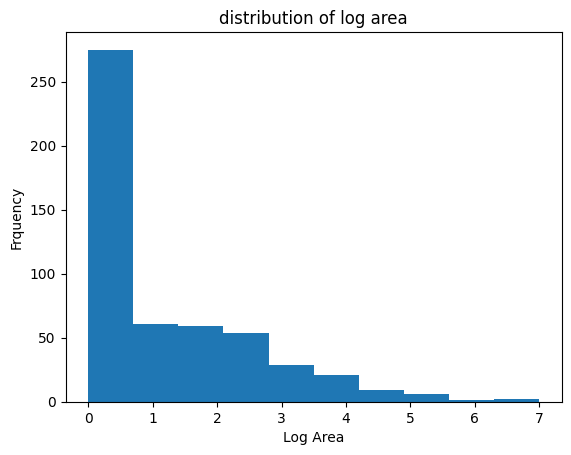

In [52]:
import matplotlib.pyplot as plt
plt.hist(df['log_area'])
plt.title('distribution of log area')
plt.xlabel('Log Area')
plt.ylabel('Frquency')
plt.show()

### Question 39
Create a **bar chart** showing the total burned area for each month.


<Axes: xlabel='month', ylabel='area'>

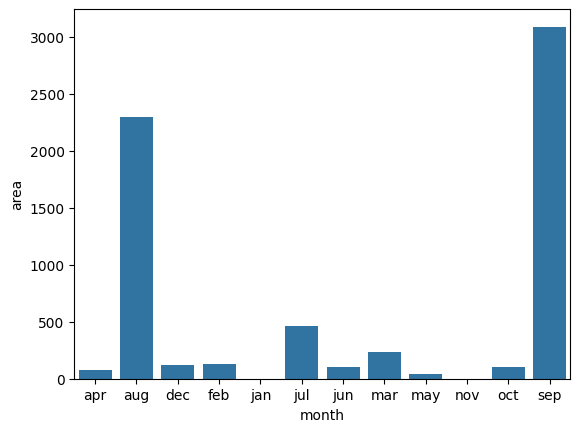

In [53]:
import seaborn as sns 
sns.barplot(df.groupby('month')['area'].sum())

### Question 40
Save `df_clean` as **ForestFires_Analyzed.csv** using `to_csv()` without saving the index.


In [54]:
df_clean.to_csv('Forest_Analyzed.csv',index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with exploring environmental data and transforming a skewed measurement before moving to advanced statistical modeling.
